# Wine Quality

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../database/84027a50-8601-40d4-8411-f8b1d838f782.csv').drop(columns='Id')
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## EDA

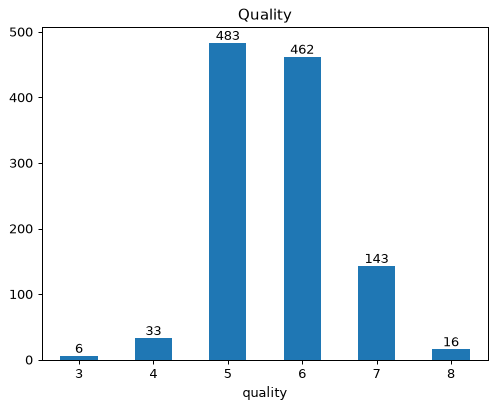

In [2]:
ax = df['quality'].value_counts().sort_index().plot.bar(rot=0, title='Quality')
ax.bar_label(ax.containers[0])
plt.show()

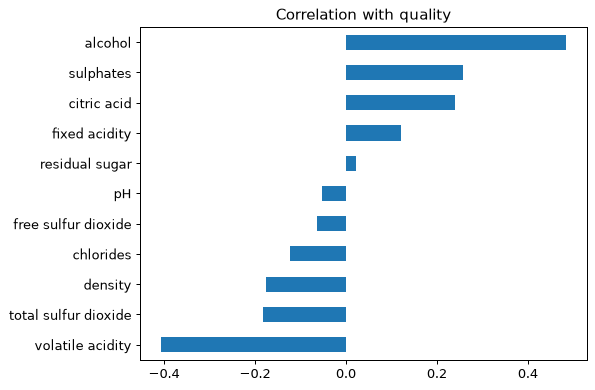

In [3]:
corr = df.corr()['quality'].drop('quality').sort_values()
corr.plot.barh(title='Correlation with quality')
plt.show()

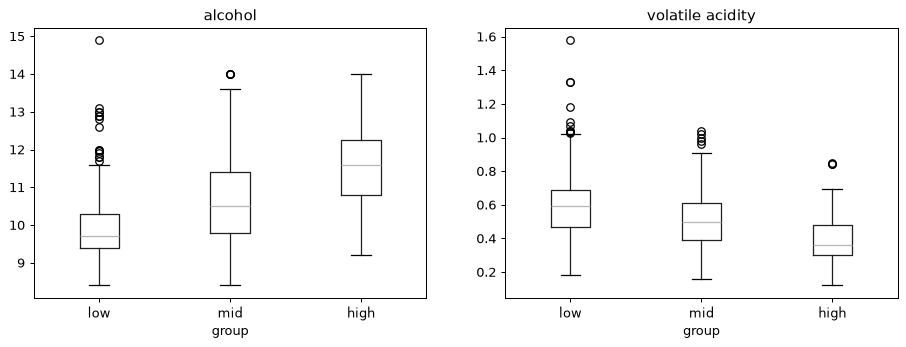

In [4]:
df['group'] = pd.cut(df['quality'], [0, 5, 6, 10], labels=['low', 'mid', 'high'])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.boxplot('alcohol', by='group', ax=ax[0], grid=False)
df.boxplot('volatile acidity', by='group', ax=ax[1], grid=False)
plt.suptitle('')
plt.show()

## Features

In [5]:
# some features are skewed, log helps
for col in ['sulphates', 'chlorides', 'total sulfur dioxide']:
    df['log_' + col] = np.log1p(df[col])

df[['sulphates', 'log_sulphates', 'chlorides', 'log_chlorides']].skew()

,0
sulphates,2.497266
log_sulphates,1.676450
chlorides,6.026360
log_chlorides,5.348773


In [6]:
# acidity features, density and pH are highly correlated with each other
df[['fixed acidity', 'citric acid', 'density', 'pH']].corr().round(2)

,fixed acidity,citric acid,density,pH
fixed acidity,1.00,0.67,0.68,-0.69
citric acid,0.67,1.00,0.38,-0.55
density,0.68,0.38,1.00,-0.35
pH,-0.69,-0.55,-0.35,1.00


In [7]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression

original = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides',
            'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
features = ['alcohol', 'volatile acidity', 'log_sulphates', 'citric acid',
            'log_total sulfur dioxide', 'log_chlorides']

cv = KFold(5, shuffle=True, random_state=42)
for name, cols in [('all 11', original), ('selected 6', features)]:
    print(name, cross_val_score(LinearRegression(), df[cols], df['quality'], cv=cv).mean().round(3))

all 11 0.356
selected 6 0.356


## Model

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

X, y = df[features], df['quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

for model in [LinearRegression(), RandomForestRegressor(random_state=42), GradientBoostingRegressor(random_state=42)]:
    pred = model.fit(X_train, y_train).predict(X_test)
    print(type(model).__name__, round(r2_score(y_test, pred), 3))

LinearRegression 0.387
RandomForestRegressor 0.439
GradientBoostingRegressor 0.417


## Tuning

In [9]:
from sklearn.model_selection import GridSearchCV

params = {
    'n_estimators': [200, 500],
    'max_depth': [None, 10, 20],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 0.5, 1.0],
}
grid = GridSearchCV(RandomForestRegressor(random_state=42), params, cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)

print(grid.best_params_)
print('cv r2:', round(grid.best_score_, 3))

{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 500}
cv r2: 0.463


## Evaluation

In [10]:
model = grid.best_estimator_
pred = model.predict(X_test)

print('R2:  ', round(r2_score(y_test, pred), 3))
print('MAE: ', round(mean_absolute_error(y_test, pred), 3))
print('RMSE:', round(mean_squared_error(y_test, pred) ** 0.5, 3))
print('MAE baseline (predict mean):', round(mean_absolute_error(y_test, [y_train.mean()] * len(y_test)), 3))

R2:   0.456
MAE:  0.427
RMSE: 0.592
MAE baseline (predict mean): 0.679


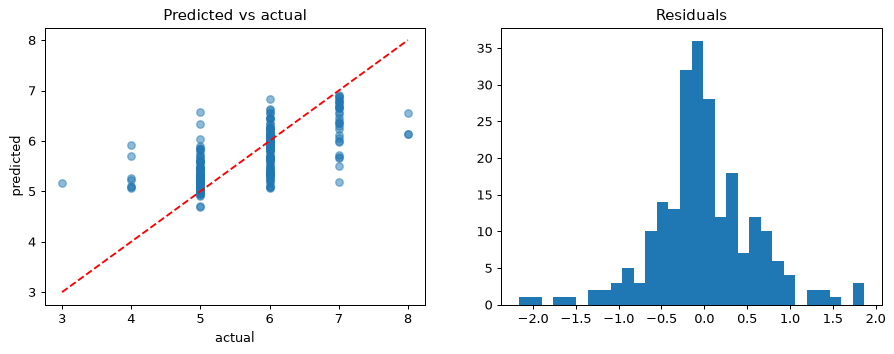

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].scatter(y_test, pred, alpha=0.5)
ax[0].plot([3, 8], [3, 8], 'r--')
ax[0].set(xlabel='actual', ylabel='predicted', title='Predicted vs actual')

ax[1].hist(y_test - pred, bins=30)
ax[1].set(title='Residuals')
plt.show()

## Interpretation

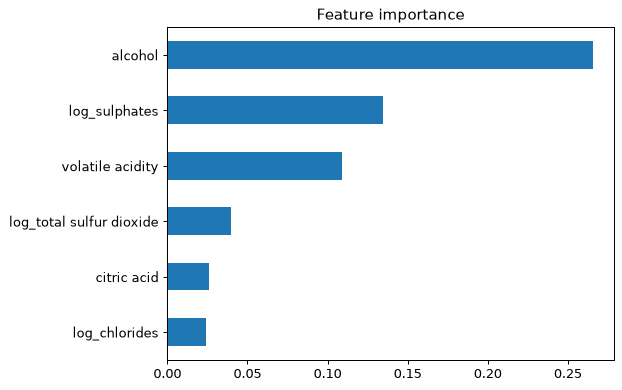

In [12]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(model, X_test, y_test, n_repeats=30, random_state=42)
pd.Series(imp.importances_mean, features).sort_values().plot.barh(title='Feature importance')
plt.show()

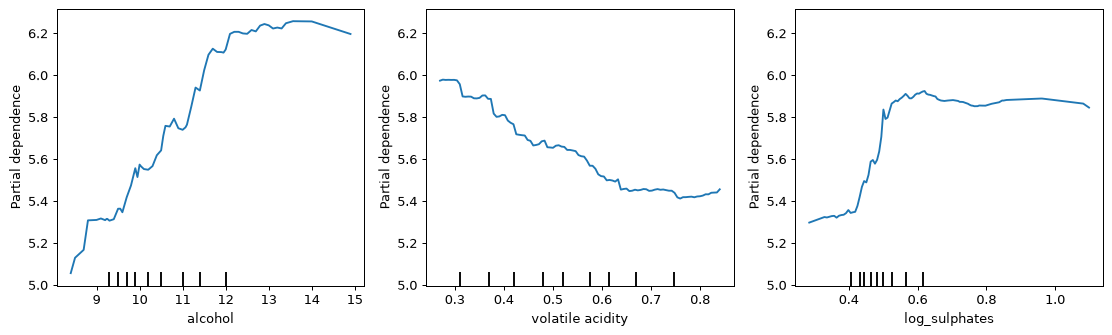

In [13]:
from sklearn.inspection import PartialDependenceDisplay

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
PartialDependenceDisplay.from_estimator(model, X_train, ['alcohol', 'volatile acidity', 'log_sulphates'], ax=ax)
plt.show()